### EXPERIMENT 1: HISTOGRAM COMPUTATION AND NORMALIZATION

Objective: Compute the histogram and probability mass function (PMF).

Tasks:
 1. Calculate the frequency of each gray level.
 2. Normalize the histogram to obtain the PMF.
 3. Verify that the sum of probabilities equals 1.

Question: Why is a normalized histogram useful when comparing images?

Total pixels: 262144
Sum of histogram: 262144
Sum of PMF: 1.0000


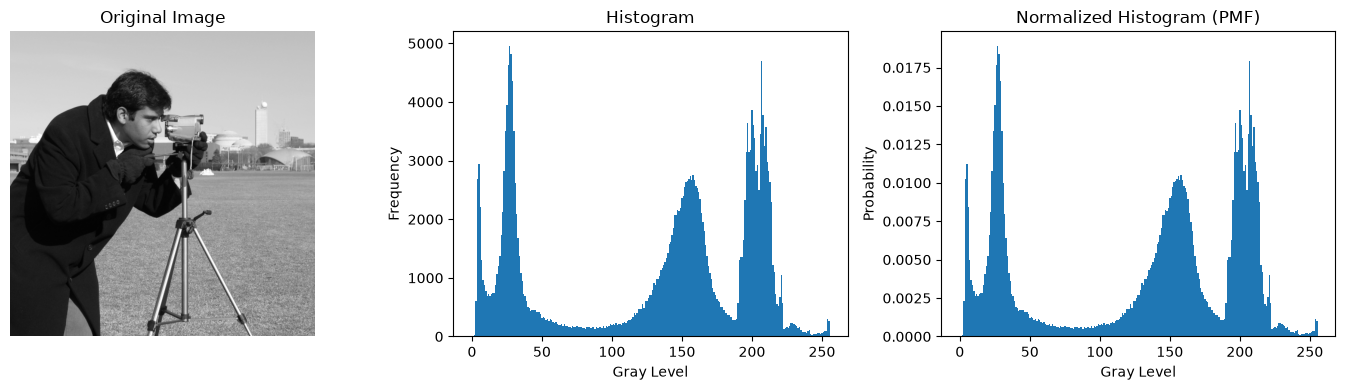

In [15]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera()

# Histogram and normalized histogram (PMF)
hist = np.bincount(img.ravel(), minlength=256)
pmf = hist / img.size

print(f"Total pixels: {img.size}")
print(f"Sum of histogram: {hist.sum()}")
print(f"Sum of PMF: {pmf.sum():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].bar(np.arange(256), hist, width=1)
axes[1].set_title("Histogram")
axes[1].set_xlabel("Gray Level")
axes[1].set_ylabel("Frequency")

axes[2].bar(np.arange(256), pmf, width=1)
axes[2].set_title("Normalized Histogram (PMF)")
axes[2].set_xlabel("Gray Level")
axes[2].set_ylabel("Probability")

plt.tight_layout()
plt.show()

### EXPERIMENT 2: INTERPRETING HISTOGRAMS

Objective: Relate histogram distributions to image brightness and contrast.

Tasks:
 1. Generate dark, bright, low-contrast, and high-contrast images.
 2. Examine their corresponding histograms.
 3. Compare the location and spread of intensity distributions.

Question: Can image contrast always be determined from histogram shape alone?

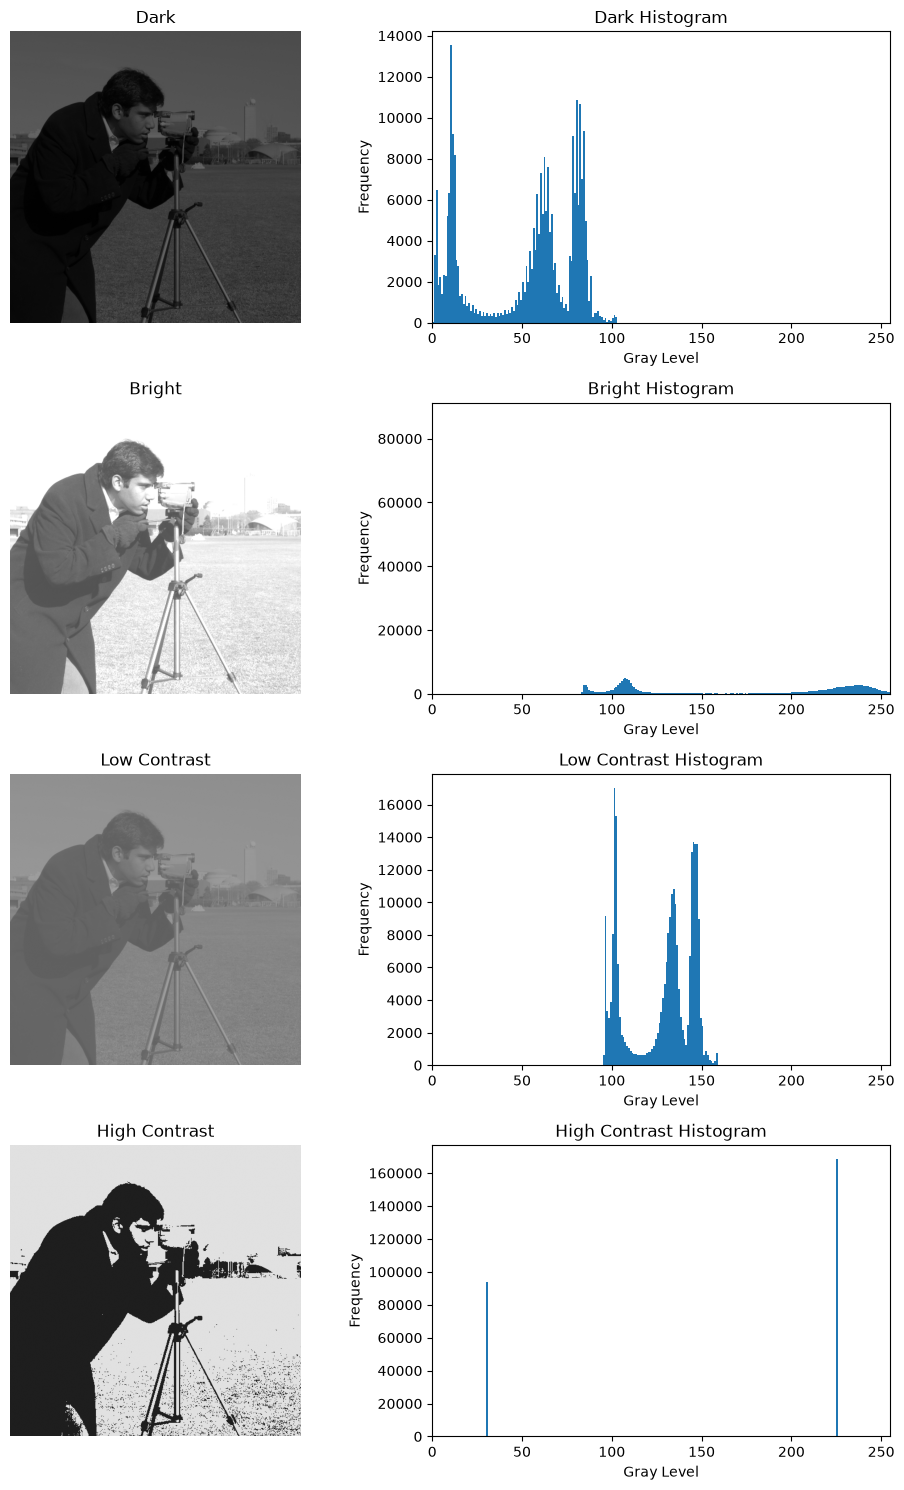

In [16]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

images = [
    np.clip(img * 0.4, 0, 255),
    np.clip(img + 80, 0, 255),
    img * 0.25 + 95,
    np.where(img < 128, 30, 225)
]

titles = ["Dark", "Bright", "Low Contrast", "High Contrast"]

fig, axes = plt.subplots(4, 2, figsize=(10, 15))

for i, (image, title) in enumerate(zip(images, titles)):
    image = image.astype(np.uint8)

    axes[i, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(title)
    axes[i, 0].axis("off")

    axes[i, 1].hist(image.ravel(), bins=256, range=(0, 256))
    axes[i, 1].set_title(f"{title} Histogram")
    axes[i, 1].set_xlim(0, 255)
    axes[i, 1].set_xlabel("Gray Level")
    axes[i, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### EXPERIMENT 3: HISTOGRAM EQUALIZATION FROM SCRATCH

Objective: Implement histogram equalization using PMF and CDF.

Tasks:
 1. Compute histogram, PMF, and CDF.
 2. Construct the intensity transformation function.
 3. Map the original pixels to equalized intensities.
 4. Compare the result with scikit-image.

Question: Why is the equalized histogram not necessarily uniform?

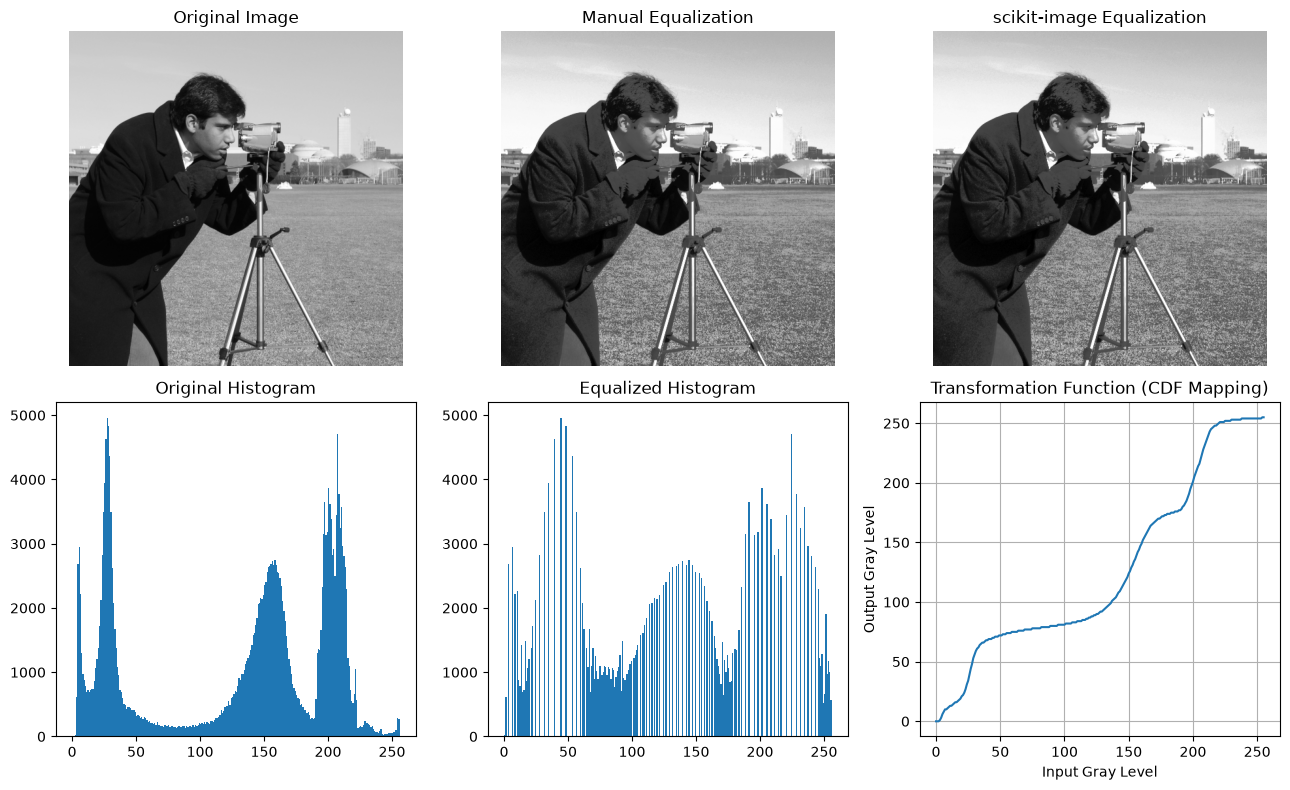

In [17]:
from skimage import data, exposure
import numpy as np
import matplotlib.pyplot as plt

img = data.camera()

# Step 1: Histogram
hist = np.bincount(img.ravel(), minlength=256)

# Step 2: PMF
pmf = hist / img.size

# Step 3: CDF
cdf = np.cumsum(pmf)

# Step 4: Normalize CDF and construct mapping
cdf_min = cdf[hist > 0][0]

if cdf_min < 1:
    mapping = np.clip(
        np.round(255 * (cdf - cdf_min) / (1 - cdf_min)),
        0, 255
    ).astype(np.uint8)
else:
    mapping = np.arange(256, dtype=np.uint8)

# Step 5: Apply mapping
equalized = mapping[img]

# Library comparison (may differ slightly due to quantization)
equalized_sk = exposure.equalize_hist(img)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(equalized, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Manual Equalization")

axes[0, 2].imshow(equalized_sk, cmap="gray", vmin=0, vmax=1)
axes[0, 2].set_title("scikit-image Equalization")

for ax in axes[0]:
    ax.axis("off")

axes[1, 0].hist(img.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Original Histogram")

axes[1, 1].hist(equalized.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Equalized Histogram")

axes[1, 2].plot(np.arange(256), mapping)
axes[1, 2].set_title("Transformation Function (CDF Mapping)")
axes[1, 2].set_xlabel("Input Gray Level")
axes[1, 2].set_ylabel("Output Gray Level")
axes[1, 2].grid(True)

plt.tight_layout()
plt.show()

### EXPERIMENT 4: HISTOGRAM SPECIFICATION (MATCHING)

Objective: Match the source image histogram to a reference distribution.

Tasks:
 1. Select source and reference images.
 2. Apply histogram matching.
 3. Compare the three images and their histograms.

Question: Why might the matched histogram differ from the reference histogram?


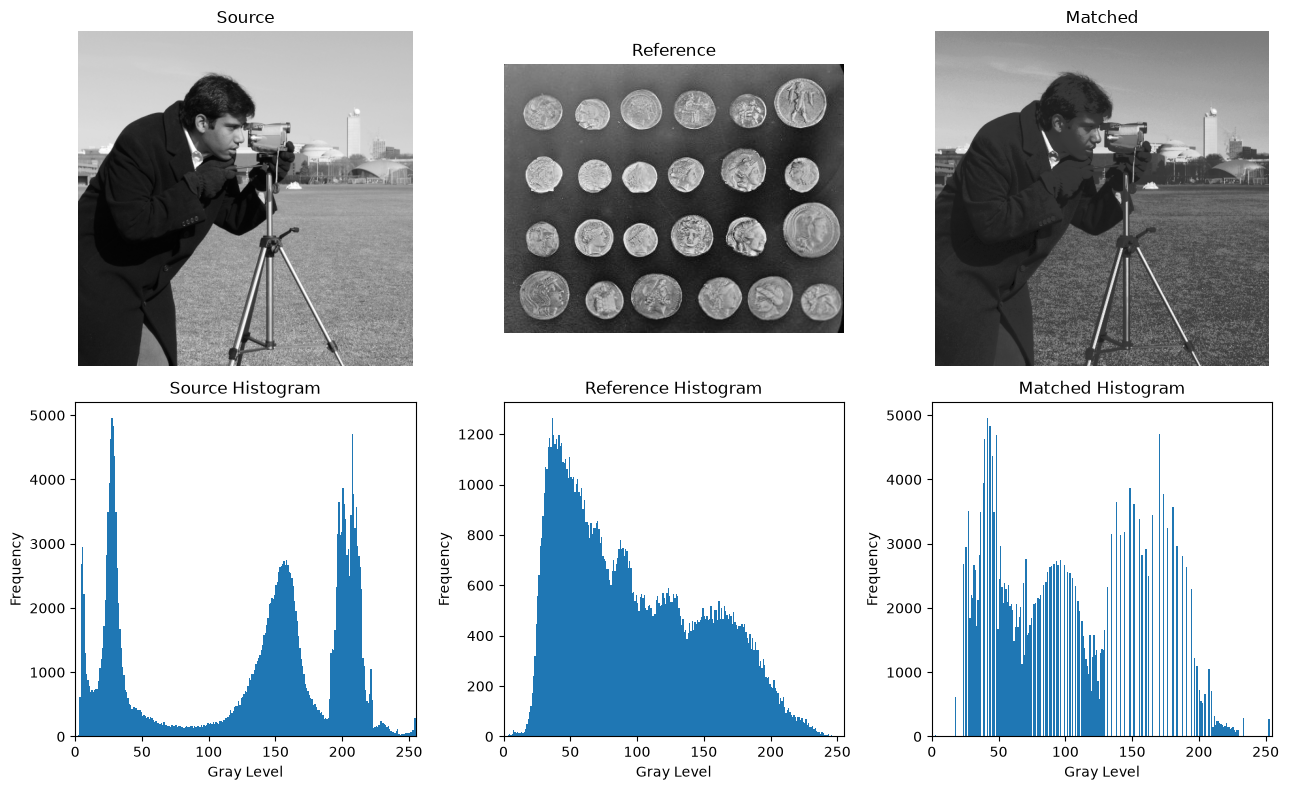

In [18]:
from skimage import data, exposure, transform
import numpy as np
import matplotlib.pyplot as plt

source = data.camera()
reference = data.coins()

# Match the histogram of the source to the reference
matched = exposure.match_histograms(source, reference)

images = [source, reference, matched]
titles = ["Source", "Reference", "Matched"]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for i, (image, title) in enumerate(zip(images, titles)):
    axes[0, i].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(title)
    axes[0, i].axis("off")

    axes[1, i].hist(image.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_title(f"{title} Histogram")
    axes[1, i].set_xlim(0, 255)
    axes[1, i].set_xlabel("Gray Level")
    axes[1, i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### EXPERIMENT 5: HISTOGRAM SLIDING

Objective: Investigate histogram shifts caused by brightness adjustment.

Tasks:
 1. Shift image intensities by +50 and -50.
 2. Compare the images and their histograms.
 3. Identify the effects of clipping at intensity boundaries.

Question: Under what condition does histogram sliding preserve contrast?

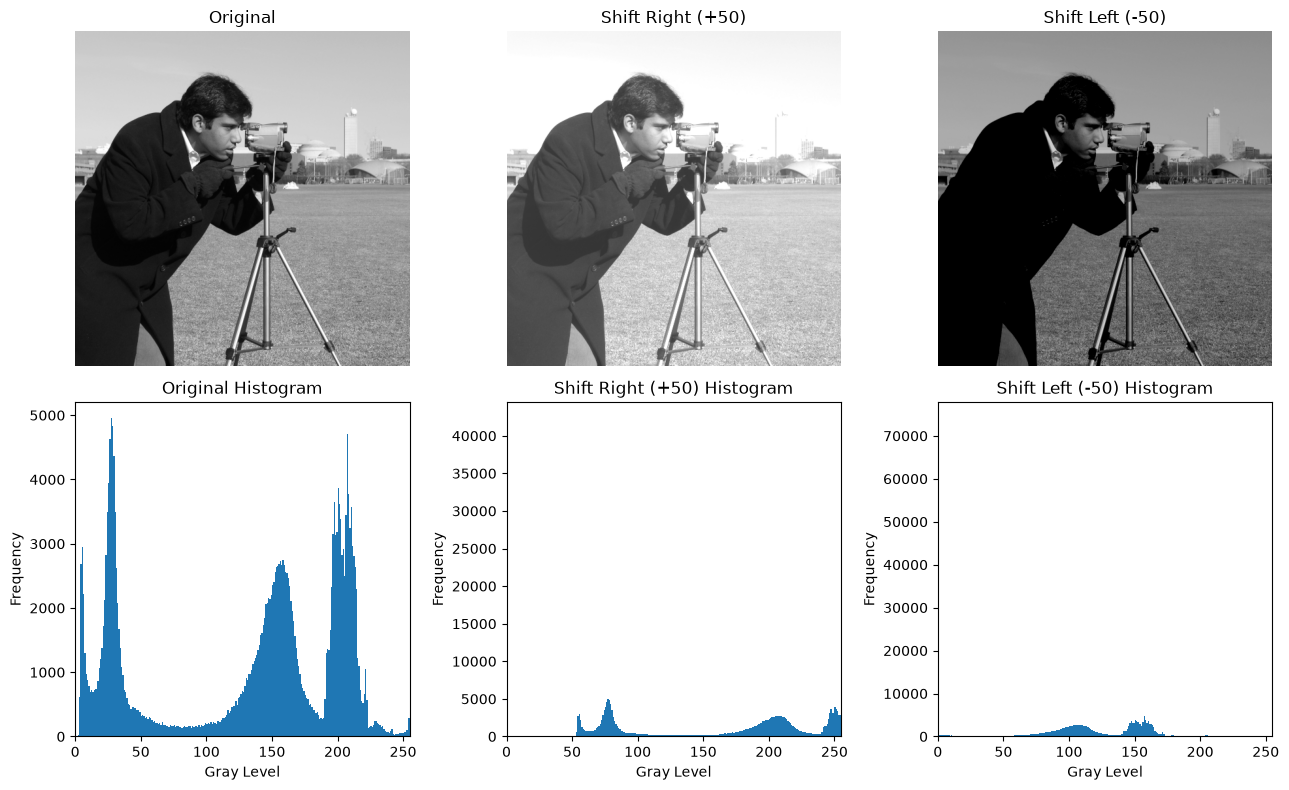

In [19]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

images = [
    img,
    np.clip(img + 50, 0, 255),
    np.clip(img - 50, 0, 255)
]

titles = ["Original", "Shift Right (+50)", "Shift Left (-50)"]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for i, (image, title) in enumerate(zip(images, titles)):
    axes[0, i].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(title)
    axes[0, i].axis("off")

    axes[1, i].hist(image.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_title(f"{title} Histogram")
    axes[1, i].set_xlim(0, 255)
    axes[1, i].set_xlabel("Gray Level")
    axes[1, i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### EXPERIMENT 6: HISTOGRAM STRETCHING

Objective: Expand a restricted intensity range to the full grayscale range.

Tasks:
 1. Generate a low-contrast image.
 2. Apply histogram stretching.
 3. Compare the images, histograms, and transformation function.

Question: How does histogram stretching differ from histogram equalization?

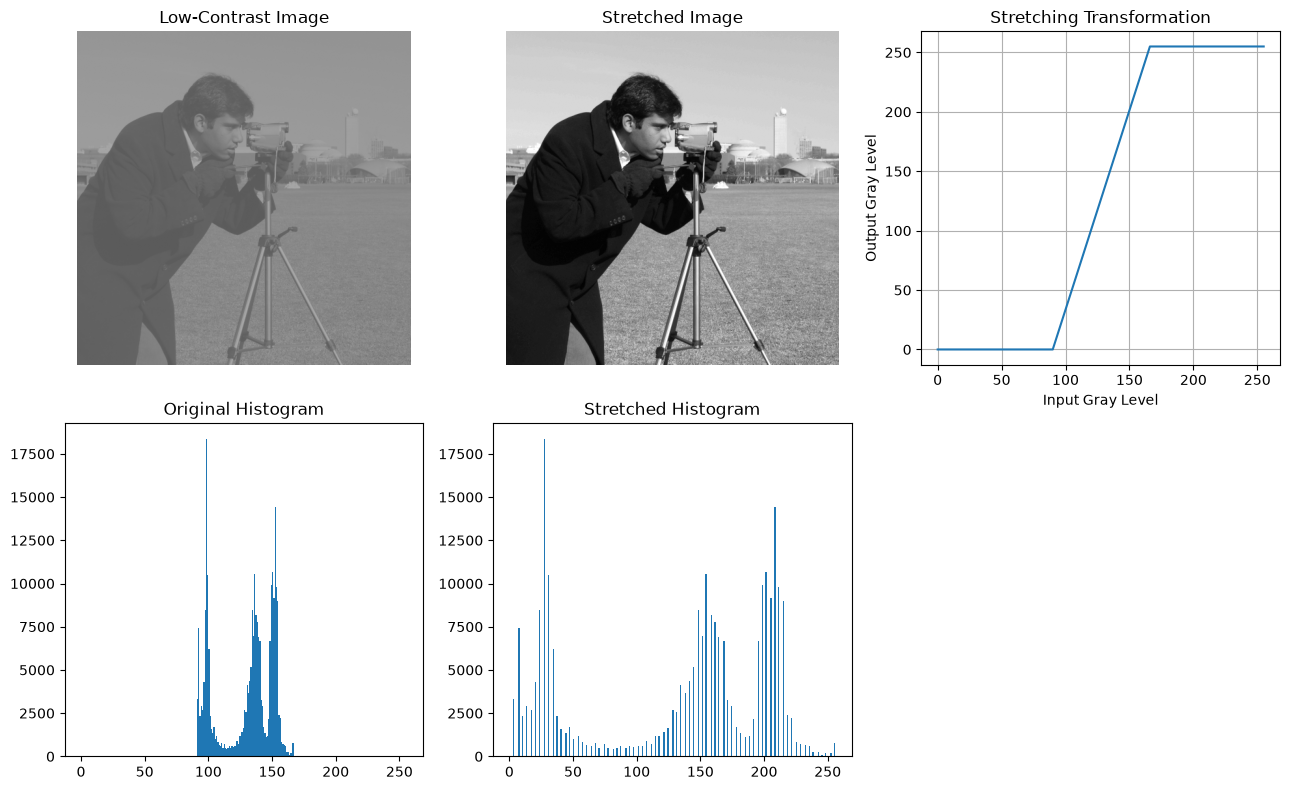

In [20]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

# Simulate a low-contrast image
low = np.round(img * 0.3 + 90).astype(np.uint8)

r_min, r_max = low.min(), low.max()

stretched = 255 * (low.astype(float) - r_min) / (r_max - r_min)
stretched = np.clip(np.round(stretched), 0, 255).astype(np.uint8)

r = np.arange(256)
s = np.clip(255 * (r - r_min) / (r_max - r_min), 0, 255)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

axes[0, 0].imshow(low, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Low-Contrast Image")

axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Stretched Image")

axes[0, 2].plot(r, s)
axes[0, 2].set_title("Stretching Transformation")
axes[0, 2].set_xlabel("Input Gray Level")
axes[0, 2].set_ylabel("Output Gray Level")
axes[0, 2].grid(True)

axes[1, 0].hist(low.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Original Histogram")

axes[1, 1].hist(stretched.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Stretched Histogram")

axes[1, 2].axis("off")

for ax in axes[0, :2]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 7: HISTOGRAM SHRINKING

Objective: Compress the intensity range to reduce image contrast.

Tasks:
 1. Map the original intensity range to [50, 140].
 2. Compare the original and processed images.
 3. Examine the histograms and transformation function.

Question: Why does shrinking reduce image contrast?

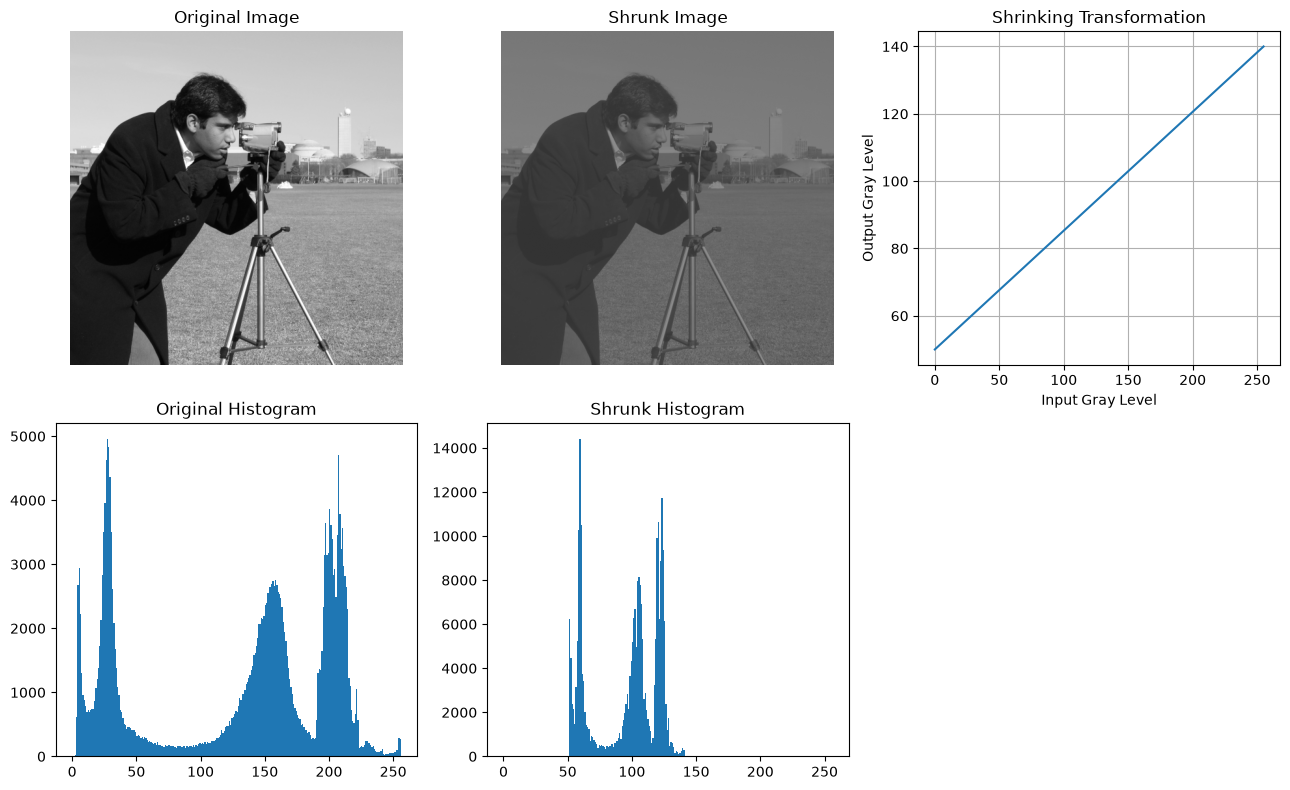

In [21]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

r_min, r_max = img.min(), img.max()
s_min, s_max = 50, 140

def shrink(r):
    return (s_max - s_min) * (r - r_min) / (r_max - r_min) + s_min

shrunk = np.clip(shrink(img), 0, 255).astype(np.uint8)

r = np.arange(256)
s = shrink(r)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(shrunk, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Shrunk Image")

axes[0, 2].plot(r, s)
axes[0, 2].set_title("Shrinking Transformation")
axes[0, 2].set_xlabel("Input Gray Level")
axes[0, 2].set_ylabel("Output Gray Level")
axes[0, 2].grid(True)

axes[1, 0].hist(img.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Original Histogram")

axes[1, 1].hist(shrunk.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Shrunk Histogram")

axes[1, 2].axis("off")

for ax in axes[0, :2]:
    ax.axis("off")

plt.tight_layout()
plt.show()